# 04 · Explainable AI (Phase 7)

**Model explained:** Logistic Regression on **eGeMAPS** (88 named voice features), the best interpretable model from Phase 6.
LightGBM on eGeMAPS is explained too, as a non-linear comparison.

**How:** SHAP, computed **out-of-fold**. Each clip is explained by a model trained without that speaker.
For logistic regression, SHAP is exact: *contribution = weight × (value − training average)* (standardised and clipped to ±5 SD, log-odds).

**Sections**
1. Global importance: which features matter, overall and per emotion
2. Feature groups (Energy / Frequency / Spectral / Temporal), compared with Paper 5
3. Direction: does a higher value push toward an emotion?
4. Cross-check with permutation importance
5. Local explanations of single clips
6. Shortcut check: the 39 "no-pitch" CREMA-D clips
7. Preview: do the two corpora agree? (formal stability test is Phase 8)

> SHAP shows what the **model** relies on. It is *association*, not proof that a feature *causes* an emotion.

In [1]:
import sys, json
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import balanced_accuracy_score, recall_score
from src.models import load_corpus, CLASSES
from src.explain import (oof_explanations, global_importance, group_shares, direction,
                         explain_clip, feature_group, linear_shap, phase6_params, _fit, GROUPS)

REDO = False
CORPORA = ["ravdess", "cremad"]
NAME = {"ravdess": "RAVDESS", "cremad": "CREMA-D"}
OUT = PROJECT_ROOT / "results" / "phase7"; OUT.mkdir(parents=True, exist_ok=True)
CACHE = PROJECT_ROOT / "data" / "processed"          # big SHAP arrays stay local (git-ignored)
FIG_DIR = PROJECT_ROOT / "results" / "figures"
BLUE, ORANGE, AQUA, YELLOW, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#0b0b0b", "#52514e"
GROUP_COLOUR = {"Energy": BLUE, "Frequency": ORANGE, "Spectral": AQUA, "Temporal": YELLOW}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.edgecolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "figure.dpi": 110})

data = {c: load_corpus(c) for c in CORPORA}
NAMES = data["ravdess"]["egemaps_names"]
assert NAMES == data["cremad"]["egemaps_names"]
print("Feature groups:", pd.Series([feature_group(n) for n in NAMES]).value_counts().to_dict())

Feature groups: {'Spectral': 43, 'Frequency': 24, 'Energy': 15, 'Temporal': 6}


## Compute out-of-fold SHAP (cached)

In [2]:
expl = {}
for c in CORPORA:
    for m in ["logreg", "lgbm"]:
        f = CACHE / f"shap_{c}_{m}.npz"
        if f.exists() and not REDO:
            z = np.load(f); expl[(c, m)] = {k: z[k] for k in z.files}
        else:
            expl[(c, m)] = oof_explanations(data[c], c, m, with_permutation=(m == "logreg"))
            np.savez_compressed(f, **expl[(c, m)])
        e = expl[(c, m)]
        print(f"{c:8s} {m:7s} SHAP {e['shap'].shape}  out-of-fold UAR "
              f"{balanced_accuracy_score(data[c]['y'], e['pred']):.3f}")
        pd.DataFrame(e["fold_imp"], columns=NAMES).to_csv(OUT / f"fold_importance_{c}_{m}.csv", index=False)
        if m == "logreg":
            pd.DataFrame(e["fold_perm"], columns=NAMES).to_csv(OUT / f"fold_permutation_{c}_{m}.csv", index=False)

ravdess  logreg  SHAP (1056, 88, 6)  out-of-fold UAR 0.554
ravdess  lgbm    SHAP (1056, 88, 6)  out-of-fold UAR 0.539
cremad   logreg  SHAP (7442, 88, 6)  out-of-fold UAR 0.514
cremad   lgbm    SHAP (7442, 88, 6)  out-of-fold UAR 0.537


The UARs above should match Phase 6 (eGeMAPS: LogReg ≈ 54.6% RAVDESS / 51.2% CREMA-D; LightGBM ≈ 52.1% / 53.3%).
That confirms we are explaining the **same models** we evaluated.

## 1. Global importance: which features matter most?

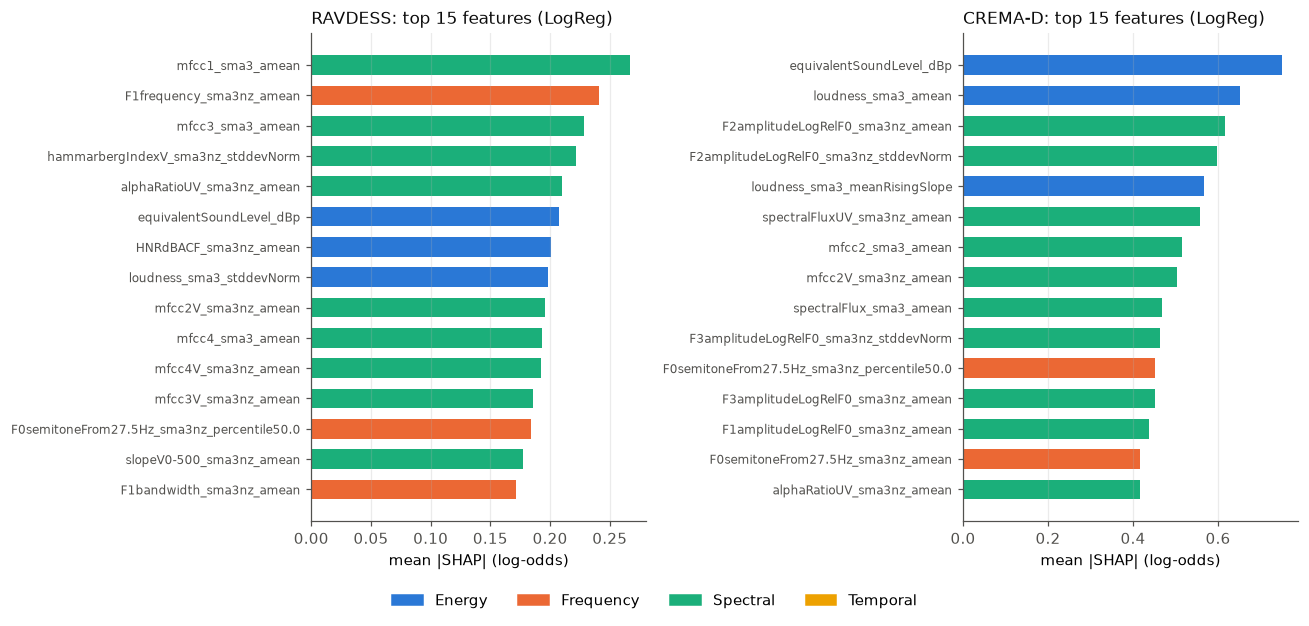

In [3]:
imp = {(c, m): global_importance(expl[(c, m)]["shap"], NAMES) for c in CORPORA for m in ["logreg", "lgbm"]}
for (c, m), df in imp.items():
    df.to_csv(OUT / f"global_importance_{c}_{m}.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
for ax, c in zip(axes, CORPORA):
    top = imp[(c, "logreg")].head(15).iloc[::-1]
    ax.barh(top["feature"], top["importance"], color=[GROUP_COLOUR[g] for g in top["group"]], height=0.65)
    ax.set_title(f"{NAME[c]}: top 15 features (LogReg)", loc="left", color=INK, fontsize=11)
    ax.set_xlabel("mean |SHAP| (log-odds)"); ax.tick_params(axis="y", labelsize=8); ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLOUR[g]) for g in GROUPS]
fig.legend(handles, GROUPS, ncol=4, frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.04, 1, 1)); fig.savefig(FIG_DIR / "p7_global_top15.png", bbox_inches="tight"); plt.show()

## 2. Feature groups: does Paper 5's *Energy > Frequency > Spectral > Temporal* hold?

In [4]:
share = pd.DataFrame({f"{NAME[c]} · {m}": group_shares(imp[(c, m)]) for c in CORPORA for m in ["logreg", "lgbm"]})
n_feats = pd.Series([feature_group(n) for n in NAMES]).value_counts().reindex(GROUPS)
share["features in group"] = n_feats.values
print("Share of total |SHAP| per group (each column sums to 1):")
print(share.round(3).to_string())
per_feature = pd.DataFrame({k: v / n_feats.values for k, v in share.drop(columns="features in group").items()})
print("\nShare divided by number of features (importance per feature):")
print((per_feature / per_feature.sum()).round(3).to_string())

Share of total |SHAP| per group (each column sums to 1):
           RAVDESS · logreg  RAVDESS · lgbm  CREMA-D · logreg  CREMA-D · lgbm  features in group
group                                                                                           
Energy                0.197           0.198             0.235           0.226                 15
Frequency             0.279           0.264             0.185           0.246                 24
Spectral              0.462           0.452             0.533           0.463                 43
Temporal              0.061           0.087             0.047           0.066                  6

Share divided by number of features (importance per feature):
           RAVDESS · logreg  RAVDESS · lgbm  CREMA-D · logreg  CREMA-D · lgbm
group                                                                        
Energy                0.287           0.268             0.359           0.320
Frequency             0.254           0.224             0.176   

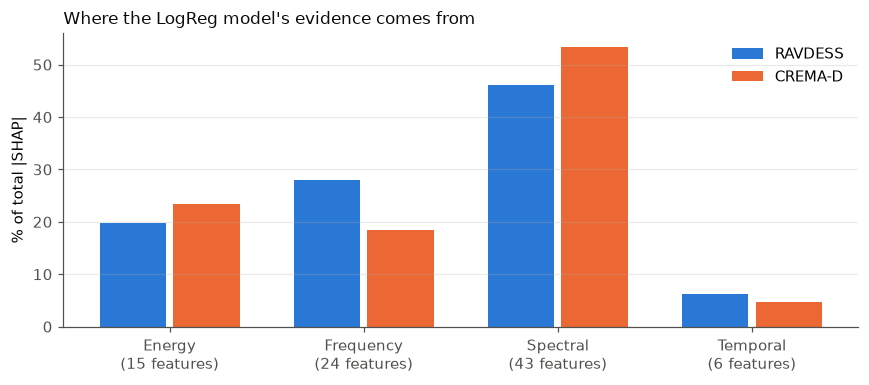

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(GROUPS)); w = 0.38
for i, (c, col) in enumerate(zip(CORPORA, [BLUE, ORANGE])):
    ax.bar(x + (i - 0.5) * w, share[f"{NAME[c]} · logreg"] * 100, w * 0.9, color=col, label=NAME[c])
ax.set_xticks(x, [f"{g}\n({n} features)" for g, n in zip(GROUPS, n_feats)])
ax.set_ylabel("% of total |SHAP|"); ax.legend(frameon=False); ax.grid(axis="x", visible=False)
ax.set_title("Where the LogReg model's evidence comes from", loc="left", color=INK, fontsize=11)
fig.tight_layout(); fig.savefig(FIG_DIR / "p7_group_shares.png", bbox_inches="tight"); plt.show()

*Read the second table too:* the Spectral group has 43 features and Temporal only 6, so raw shares favour big groups.
P5 ranked groups by information content, which is closer to the per-feature view.

## 3. Per-emotion drivers and their direction
For each emotion: the 4 features with the largest mean |SHAP| for that emotion's score, and whether a **higher** value pushes **toward** (↑) or **away from** (↓) it.

In [6]:
rows = []
for c in CORPORA:
    sv, X = expl[(c, "logreg")]["shap"], data[c]["egemaps"]
    for k, emo in enumerate(CLASSES):
        d = direction(sv, X, k)
        mag = np.abs(sv[:, :, k]).mean(axis=0)
        for j in np.argsort(-mag)[:4]:
            rows.append({"corpus": NAME[c], "emotion": emo, "feature": NAMES[j], "group": feature_group(NAMES[j]),
                         "mean|SHAP|": round(float(mag[j]), 3),
                         "higher value →": "toward ↑" if d[j] > 0 else "away ↓"})
drivers = pd.DataFrame(rows)
drivers.to_csv(OUT / "per_emotion_drivers.csv", index=False)
for c in CORPORA:
    print(f"\n===== {NAME[c]} =====")
    print(drivers[drivers.corpus == NAME[c]].drop(columns="corpus").to_string(index=False))


===== RAVDESS =====
emotion                                    feature     group  mean|SHAP| higher value →
neutral                   equivalentSoundLevel_dBp    Energy       0.388         away ↓
neutral                   loudness_sma3_stddevNorm    Energy       0.361       toward ↑
neutral            loudness_sma3_stddevRisingSlope    Energy       0.350         away ↓
neutral                           mfcc1_sma3_amean  Spectral       0.340       toward ↑
  happy                           mfcc4_sma3_amean  Spectral       0.480       toward ↑
  happy F0semitoneFrom27.5Hz_sma3nz_percentile50.0 Frequency       0.467       toward ↑
  happy                           mfcc3_sma3_amean  Spectral       0.425       toward ↑
  happy     F0semitoneFrom27.5Hz_sma3nz_stddevNorm Frequency       0.340       toward ↑
    sad                   F1frequency_sma3nz_amean Frequency       0.416       toward ↑
    sad                   alphaRatioV_sma3nz_amean  Spectral       0.334         away ↓
    sad    

## 4. Cross-check: does permutation importance agree with SHAP?
Permutation importance = how much test UAR drops when one feature is randomly shuffled. A completely different method.

In [7]:
agree = {}
for c in CORPORA:
    shap_rank = expl[(c, "logreg")]["fold_imp"].mean(axis=0)
    perm_rank = expl[(c, "logreg")]["fold_perm"].mean(axis=0)
    rho = spearmanr(shap_rank, perm_rank).statistic
    top_s, top_p = set(np.argsort(-shap_rank)[:10]), set(np.argsort(-perm_rank)[:10])
    agree[c] = {"spearman": round(float(rho), 3), "top10_overlap": len(top_s & top_p)}
    print(f"{NAME[c]}: Spearman(SHAP, permutation) = {rho:.2f};  top-10 overlap = {len(top_s & top_p)}/10")
    print("   top-5 by permutation:", [NAMES[j] for j in np.argsort(-perm_rank)[:5]])

RAVDESS: Spearman(SHAP, permutation) = 0.79;  top-10 overlap = 5/10
   top-5 by permutation: ['alphaRatioUV_sma3nz_amean', 'mfcc1_sma3_amean', 'F1frequency_sma3nz_amean', 'mfcc4_sma3_amean', 'mfcc3_sma3_amean']
CREMA-D: Spearman(SHAP, permutation) = 0.96;  top-10 overlap = 7/10
   top-5 by permutation: ['equivalentSoundLevel_dBp', 'loudness_sma3_meanRisingSlope', 'F3amplitudeLogRelF0_sma3nz_stddevNorm', 'loudness_sma3_amean', 'alphaRatioUV_sma3nz_amean']


If agreement is only moderate, a likely reason is **correlated features** (e.g. several loudness statistics).
Permutation importance under-rates a feature when a correlated twin still carries the information; SHAP spreads credit between them.

## 5. Local explanations: why did *this* clip get *this* prediction?

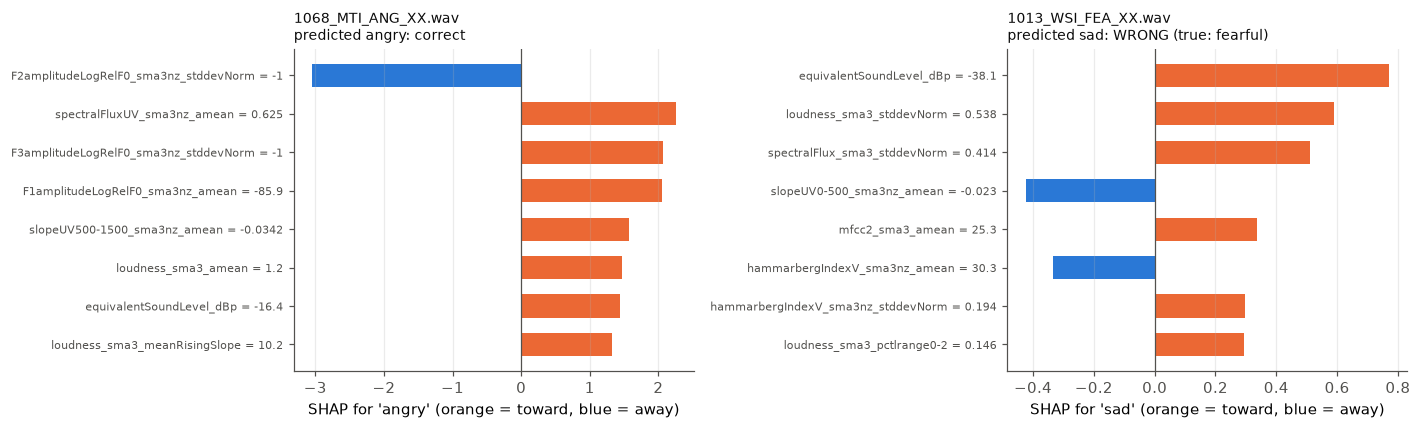

Predicted **sad** (true: fearful). Top features for the 'sad' score:
  - equivalentSoundLevel_dBp = -38.1  pushed TOWARD sad (+0.77)
  - loudness_sma3_stddevNorm = 0.538  pushed TOWARD sad (+0.59)
  - spectralFlux_sma3_stddevNorm = 0.414  pushed TOWARD sad (+0.51)
  - slopeUV0-500_sma3nz_amean = -0.023  pushed AWAY from sad (-0.42)
  - mfcc2_sma3_amean = 25.3  pushed TOWARD sad (+0.34)


In [8]:
def plot_local(c, i, ax, top=8):
    sv, X, y, pred = expl[(c, "logreg")]["shap"], data[c]["egemaps"], data[c]["y"], expl[(c, "logreg")]["pred"]
    k = int(pred[i]); contrib = sv[i, :, k]
    order = np.argsort(-np.abs(contrib))[:top][::-1]
    ax.barh([f"{NAMES[j]} = {X[i, j]:.3g}" for j in order], contrib[order],
            color=[ORANGE if v > 0 else BLUE for v in contrib[order]], height=0.6)
    ax.axvline(0, color=MUTED, lw=0.8)
    ok = "correct" if pred[i] == y[i] else f"WRONG (true: {CLASSES[int(y[i])]})"
    ax.set_title(f"{data[c]['meta'].loc[i, 'file']}\npredicted {CLASSES[k]}: {ok}", loc="left", color=INK, fontsize=9)
    ax.set_xlabel(f"SHAP for '{CLASSES[k]}' (orange = toward, blue = away)"); ax.tick_params(axis="y", labelsize=7)
    ax.grid(axis="y", visible=False)

c = "cremad"
y, pred, sv = data[c]["y"], expl[(c, "logreg")]["pred"], expl[(c, "logreg")]["shap"]
# pick TYPICAL clips (median evidence), not extreme ones, so the examples are representative
evidence = np.array([sv[i, :, pred[i]].sum() for i in range(len(y))])
def typical(mask):
    idx = np.where(mask)[0]
    return int(idx[np.argmin(np.abs(evidence[idx] - np.median(evidence[idx])))])
angry = CLASSES.index("angry"); fear = CLASSES.index("fearful"); sad = CLASSES.index("sad")
i_ok = typical((y == angry) & (pred == angry))     # a typical correct 'angry'
i_bad = typical((y == fear) & (pred == sad))       # a typical error: fearful predicted as sad
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_local(c, i_ok, axes[0]); plot_local(c, i_bad, axes[1])
fig.tight_layout(); fig.savefig(FIG_DIR / "p7_local_examples.png", bbox_inches="tight"); plt.show()
print(explain_clip(i_bad, sv, data[c]["egemaps"], NAMES, pred, y))

## 6. Shortcut check: the 39 "no-pitch" CREMA-D clips
openSMILE found no pitch in 39 quiet clips (Phase 5), so their pitch features read **0**. Does the model learn "no pitch → sad"?

In [9]:
c = "cremad"; d = data[c]; X, y = d["egemaps"], d["y"]
f0 = NAMES.index("F0semitoneFrom27.5Hz_sma3nz_amean")
nop = X[:, f0] == 0
sv, pred = expl[(c, "logreg")]["shap"], expl[(c, "logreg")]["pred"]
print(f"no-pitch clips: {nop.sum()}  | true labels: {pd.Series(np.array(CLASSES)[y[nop]]).value_counts().to_dict()}")
print(f"predicted labels:                 {pd.Series(np.array(CLASSES)[pred[nop]]).value_counts().to_dict()}")
pitch_cols = [j for j, n in enumerate(NAMES) if n.startswith("F0semitone")]
print(f"mean SHAP of pitch features toward 'sad': no-pitch clips {sv[nop][:, pitch_cols, sad].sum(1).mean():+.2f}  "
      f"vs other clips {sv[~nop][:, pitch_cols, sad].sum(1).mean():+.2f}")

# Sensitivity: retrain without these clips (same folds and hyperparameters)
params = phase6_params(c, "logreg"); keep = ~nop
pred_k = np.full(len(y), -1)
for k in sorted(np.unique(d["folds"])):
    tr, te = (d["folds"] != k) & keep, (d["folds"] == k) & keep
    pred_k[te] = _fit("logreg", params[k], X[tr], y[tr]).predict(X[te])
base_sad = recall_score(y[keep], pred[keep], labels=[sad], average=None)[0]
new_sad = recall_score(y[keep], pred_k[keep], labels=[sad], average=None)[0]
shortcut = {"n_no_pitch": int(nop.sum()),
            "uar_with": round(float(balanced_accuracy_score(y[keep], pred[keep])), 4),
            "uar_without": round(float(balanced_accuracy_score(y[keep], pred_k[keep])), 4),
            "sad_recall_with": round(float(base_sad), 4), "sad_recall_without": round(float(new_sad), 4)}
print("Evaluated on the same 7,4xx normal clips:", shortcut)

no-pitch clips: 39  | true labels: {'sad': 21, 'disgust': 12, 'fearful': 5, 'happy': 1}
predicted labels:                 {'sad': 26, 'disgust': 13}
mean SHAP of pitch features toward 'sad': no-pitch clips +0.08  vs other clips -0.00
Evaluated on the same 7,4xx normal clips: {'n_no_pitch': 39, 'uar_with': 0.5141, 'uar_without': 0.514, 'sad_recall_with': 0.5776, 'sad_recall_without': 0.5816}


**How to read this:** if removing these clips from training barely changes UAR and sad recall, the model is **not** relying on a "no pitch → sad" shortcut.
A big drop in sad recall would mean it partly was.

## 7. Preview: do RAVDESS and CREMA-D models rely on the same features?
A first look only; the formal test with seeds, folds and a random baseline is Phase 8 (H2).

In [10]:
preview = {}
for m in ["logreg", "lgbm"]:
    a = expl[("ravdess", m)]["fold_imp"].mean(0); b = expl[("cremad", m)]["fold_imp"].mean(0)
    rho = spearmanr(a, b).statistic
    ta, tb = set(np.argsort(-a)[:10]), set(np.argsort(-b)[:10])
    preview[m] = {"spearman": round(float(rho), 3), "top10_jaccard": round(len(ta & tb) / len(ta | tb), 3),
                  "shared_top10": sorted(NAMES[j] for j in ta & tb)}
    print(f"{m}: Spearman = {rho:.2f}, top-10 Jaccard = {preview[m]['top10_jaccard']:.2f}")
    print("   shared top-10:", preview[m]["shared_top10"])

logreg: Spearman = 0.54, top-10 Jaccard = 0.11
   shared top-10: ['equivalentSoundLevel_dBp', 'mfcc2V_sma3nz_amean']
lgbm: Spearman = 0.24, top-10 Jaccard = 0.11
   shared top-10: ['F0semitoneFrom27.5Hz_sma3nz_stddevNorm', 'spectralFluxUV_sma3nz_amean']


In [11]:
summary = {
    "oof_uar": {f"{c}_{m}": round(float(balanced_accuracy_score(data[c]['y'], expl[(c, m)]['pred'])), 4)
                for c in CORPORA for m in ["logreg", "lgbm"]},
    "top10": {f"{c}_{m}": imp[(c, m)].head(10)["feature"].tolist() for c in CORPORA for m in ["logreg", "lgbm"]},
    "group_share": share.drop(columns="features in group").round(4).to_dict(),
    "shap_vs_permutation": agree,
    "no_pitch_shortcut_check": shortcut,
    "cross_corpus_preview": preview,
}
(PROJECT_ROOT / "results" / "phase7_summary.json").write_text(json.dumps(summary, indent=2))
print("saved results/phase7_summary.json")

saved results/phase7_summary.json
